# Parcial práctico · Corte 3 (Semana 15)
**Nombre:** Julian Cabrera Murcia  



In [15]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sqlite3
plt.rcParams["figure.figsize"] = (9, 4)

## Problema 1 — Serie de tiempo
Se usa una serie diaria de ventas (2023–2024). Si tienes un CSV, reemplaza la celda de datos por:
`df = pd.read_csv("ventas.csv", parse_dates=["fecha"], index_col="fecha")`

In [16]:
# Datos de ejemplo: tendencia + estacionalidad anual (pico a mitad de año) + semanal + ruido
rng = np.random.default_rng(42)
fechas = pd.date_range("2023-01-01", "2024-12-31", freq="D")
t = np.arange(len(fechas))
valores = (100 + 0.08*t
           + 15*np.sin(2*np.pi*(fechas.dayofyear-80)/365.25)
           + 5*(fechas.dayofweek >= 5)
           + rng.normal(0, 4, len(t)))
df = pd.DataFrame({"fecha": fechas, "ventas": valores})

# 1) Fecha como índice
df = df.set_index("fecha").sort_index()
df.head()

,ventas
fecha,
2023-01-01,91.554072
2023-01-02,81.311680
2023-01-03,88.614157
2023-01-04,89.519651
2023-01-05,78.102578


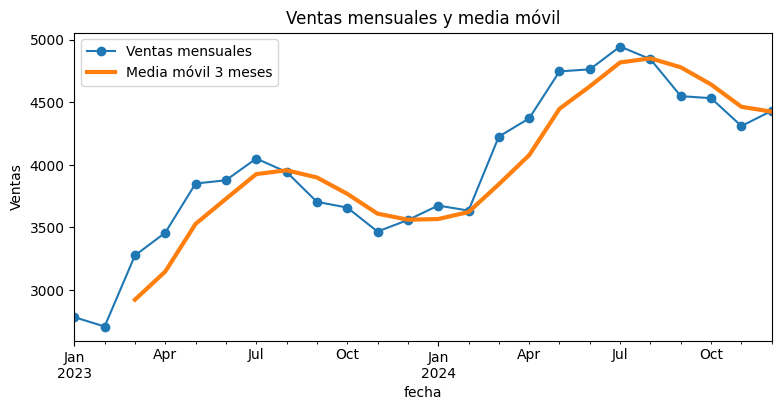

In [17]:
# 2) Agregar por periodo (resample mensual: suma de ventas)
mensual = df["ventas"].resample("MS").sum()

# 3) Media móvil (3 meses) sobre la serie mensual
mm3 = mensual.rolling(window=3).mean()

ax = mensual.plot(marker="o", label="Ventas mensuales")
mm3.plot(ax=ax, linewidth=3, label="Media móvil 3 meses")
ax.set_title("Ventas mensuales y media móvil"); ax.set_ylabel("Ventas"); ax.legend(); plt.show()

Pendiente de la tendencia: 72.1 unidades/mes (>0 = crecimiento)
Mes con mayor efecto estacional: 7 | menor: 2


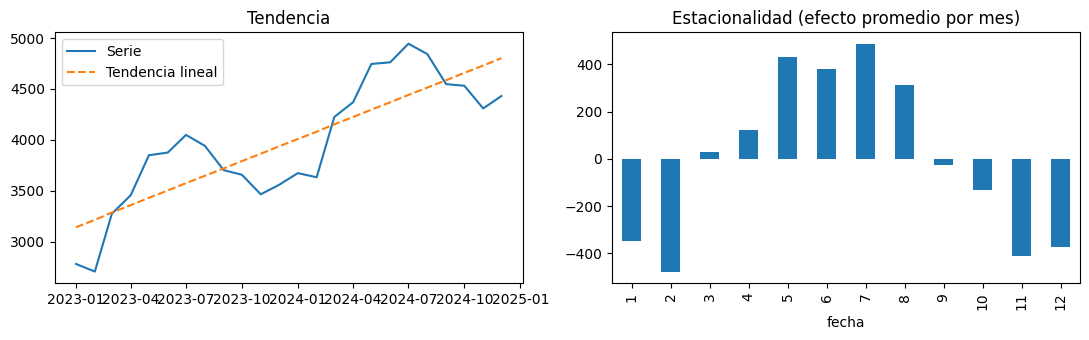

In [18]:
# 4) Tendencia y estacionalidad
x = np.arange(len(mensual))
pendiente, intercepto = np.polyfit(x, mensual.values, 1)
tendencia = pendiente*x + intercepto
residuo = mensual.values - tendencia
indice_estacional = pd.Series(residuo, index=mensual.index).groupby(mensual.index.month).mean()

print(f"Pendiente de la tendencia: {pendiente:.1f} unidades/mes (>0 = crecimiento)")
print("Mes con mayor efecto estacional:", indice_estacional.idxmax(), "| menor:", indice_estacional.idxmin())

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(mensual.index, mensual.values, label="Serie"); axs[0].plot(mensual.index, tendencia, "--", label="Tendencia lineal")
axs[0].set_title("Tendencia"); axs[0].legend()
indice_estacional.plot(kind="bar", ax=axs[1], title="Estacionalidad (efecto promedio por mes)")
plt.tight_layout(); plt.show()

### Interpretación P1 — Serie de tiempo
**Qué se hizo:** la serie diaria se pasó a índice de fechas, se agregó por mes con `resample("MS")` (suma de ventas) y se suavizó con una media móvil de 3 meses.

**Tendencia (creciente):** la recta ajustada tiene pendiente ≈ **+72 unidades por mes**. Las ventas pasaron de ≈ 42.330 en 2023 a ≈ 53.017 en 2024, un crecimiento de **≈ 25 %**. La media móvil sube de ≈ 2.922 (mar-2023) a ≈ 4.424 (dic-2024), lo que confirma que el aumento es sostenido y no un pico aislado.

**Estacionalidad (anual):** el patrón se repite en los dos años. Los meses altos son **mayo–agosto** (máximo en **julio**, ≈ +488 sobre la tendencia) y los bajos son **enero–febrero** y **noviembre–diciembre** (mínimo en **febrero**, ≈ −477). Como el ciclo se repite cada 12 meses, es estacionalidad y no tendencia. Parte del valle de febrero se debe a que tiene menos días; para comparar meses con justicia convendría usar el promedio diario.

**Patrón semanal:** en la serie diaria los fines de semana venden en promedio ≈ 5 unidades más que los días de semana; no se ve en la serie mensual porque `resample` lo suma.

**Media móvil:** suaviza el ruido y muestra la dirección general, pero introduce un retraso y deja los 2 primeros valores en `NaN`. *Nota: los datos son de ejemplo (generados), por eso los meses pico y valle corresponden a este conjunto.*

## Problema 2 — Visualización efectiva
### 2.1 Gráfico correcto para cada pregunta
| Pregunta | Gráfico | Justificación |
|---|---|---|
| **Evolución:** ¿cómo cambiaron las ventas mes a mes? | **Líneas** | El orden temporal se lee como continuidad; muestra tendencia y estacionalidad. |
| **Comparación:** ¿qué categoría/sucursal vende más? | **Barras** (horizontales, ordenadas) | La longitud sobre una base común es lo que el ojo compara con más precisión. |
| **Proporción:** ¿qué parte del total es cada segmento? | **Dona/torta solo con pocas categorías (≤4–5)**; si hay más, barras 100 % apiladas o barras ordenadas | Representa parte-todo, pero los ángulos son difíciles de comparar con muchas porciones. |

### 2.2 Errores de diseño y corrección

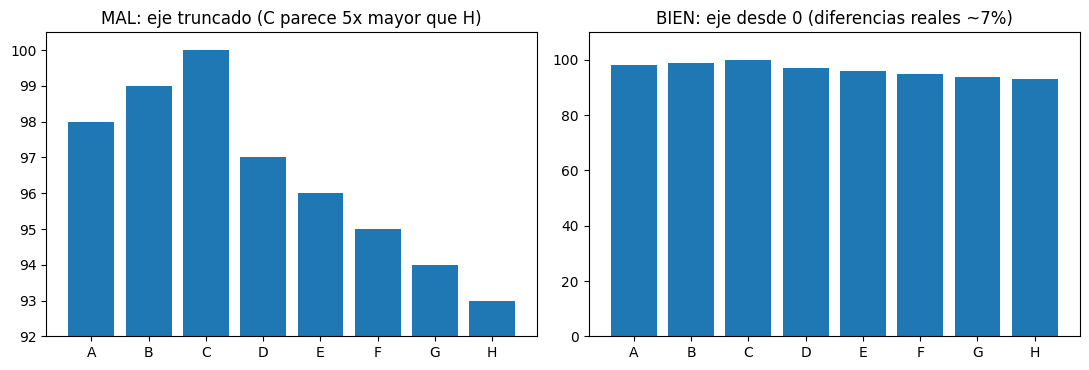

In [19]:
cat = pd.Series({"A":98, "B":99, "C":100, "D":97, "E":96, "F":95, "G":94, "H":93})

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
# ERROR: eje Y truncado exagera diferencias mínimas
axs[0].bar(cat.index, cat.values); axs[0].set_ylim(92, 100.5)
axs[0].set_title("MAL: eje truncado (C parece 5x mayor que H)")
# CORRECCIÓN: eje desde 0
axs[1].bar(cat.index, cat.values); axs[1].set_ylim(0, 110)
axs[1].set_title("BIEN: eje desde 0 (diferencias reales ~7%)")
plt.tight_layout(); plt.show()

**Interpretación:** con el eje truncado en 92, la barra de C (100) parece unas 8 veces más alta que la de H (93), cuando en realidad solo es ≈ 7 % mayor. Con el eje desde 0 las barras son casi iguales y la lectura es honesta. Regla: en barras, la longitud representa el valor, así que el eje debe empezar en 0.

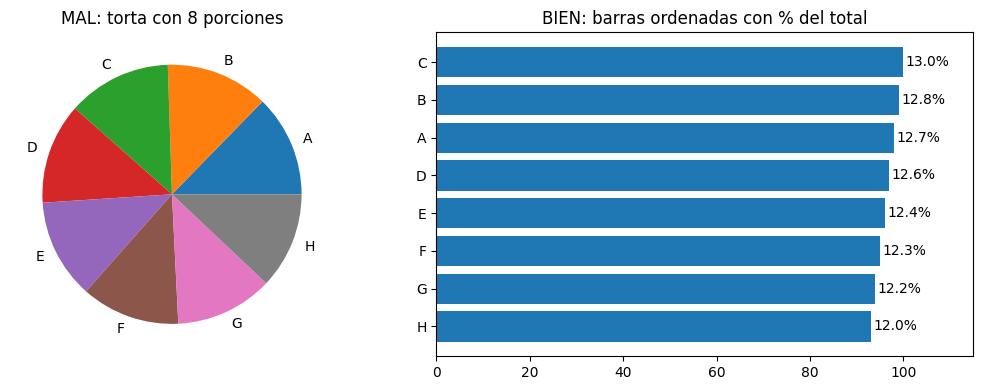

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
# ERROR: torta saturada (8 porciones casi iguales, imposible comparar)
axs[0].pie(cat.values, labels=cat.index); axs[0].set_title("MAL: torta con 8 porciones")
# CORRECCIÓN: barras horizontales ordenadas con etiqueta de valor
orden = cat.sort_values()
axs[1].barh(orden.index, orden.values, color="tab:blue")
for i, v in enumerate(orden.values): axs[1].text(v+0.5, i, f"{v/cat.sum():.1%}", va="center")
axs[1].set_title("BIEN: barras ordenadas con % del total"); axs[1].set_xlim(0, 115)
plt.tight_layout(); plt.show()

**Interpretación:** en la torta las 8 porciones son casi del mismo tamaño y no se puede saber cuál es mayor sin mirar los números. En las barras horizontales ordenadas, con el porcentaje de cada categoría, se ve el ranking de un vistazo (C lidera con ≈ 13 % y H cierra con ≈ 12 %) y también que las diferencias son pequeñas.

### Interpretación P2 — Visualización
Cada pregunta se asocia con el gráfico que facilita la lectura correcta: **evolución → líneas** (se ve la continuidad en el tiempo), **comparación → barras** (se comparan longitudes con una base común) y **proporción → torta con pocas categorías** (parte del todo). Los dos errores mostrados distorsionan la percepción: el **eje truncado exagera** diferencias pequeñas y la **torta saturada oculta** el orden entre categorías. Las correcciones (eje desde 0 y barras ordenadas con etiquetas) hacen que el gráfico comunique lo que dicen los datos.

## Problema 3 — Optimización y métricas
### 3.1 Consulta lenta vs optimizada
**Consulta lenta**
```sql
SELECT *
FROM ventas
WHERE YEAR(fecha) = 2024 AND MONTH(fecha) = 3;
```
**Consulta optimizada**
```sql
SELECT id_venta, fecha, id_cliente, total      -- solo columnas necesarias
FROM ventas
WHERE fecha >= '2024-03-01' AND fecha < '2024-04-01';  -- filtro por rango

CREATE INDEX idx_ventas_fecha ON ventas(fecha);
```
**Por qué mejora**
1. `SELECT *` trae columnas innecesarias (más I/O y red); nombrar columnas reduce datos y permite índices cubrientes.
2. Una función sobre la columna (`YEAR(fecha)`) impide usar el índice (no es *sargable*) y obliga a evaluar fila por fila (full scan). Con un rango, el motor compara `fecha` directamente.
3. El índice sobre `fecha` permite buscar el rango sin recorrer toda la tabla.

Demostración con SQLite (plan de ejecución antes y después):

In [21]:
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE ventas(id_venta INTEGER PRIMARY KEY, fecha TEXT, id_cliente INT, total REAL, notas TEXT)")
con.executemany("INSERT INTO ventas(fecha,id_cliente,total,notas) VALUES (?,?,?,?)",
    [(d.strftime("%Y-%m-%d"), int(i%500), float(v), "x") for i,(d,v) in enumerate(df["ventas"].items())])

lenta = "SELECT * FROM ventas WHERE strftime('%Y',fecha)='2024' AND strftime('%m',fecha)='03'"
rapida = "SELECT id_venta, fecha, id_cliente, total FROM ventas WHERE fecha >= '2024-03-01' AND fecha < '2024-04-01'"

print("LENTA (sin índice):   ", con.execute("EXPLAIN QUERY PLAN "+lenta).fetchall())
con.execute("CREATE INDEX idx_ventas_fecha ON ventas(fecha)")
print("LENTA (con índice):   ", con.execute("EXPLAIN QUERY PLAN "+lenta).fetchall(), "<- sigue en SCAN")
print("OPTIMIZADA (índice):  ", con.execute("EXPLAIN QUERY PLAN "+rapida).fetchall(), "<- SEARCH usando índice")

LENTA (sin índice):    [(2, 0, 216, 'SCAN ventas')]
LENTA (con índice):    [(2, 0, 216, 'SCAN ventas')] <- sigue en SCAN
OPTIMIZADA (índice):   [(3, 0, 165, 'SEARCH ventas USING INDEX idx_ventas_fecha (fecha>? AND fecha<?)')] <- SEARCH usando índice


### Interpretación P3.1 — Optimización
Los planes de ejecución confirman la teoría:
- **Consulta lenta, sin índice:** `SCAN ventas` → recorre toda la tabla.
- **Consulta lenta, con índice:** sigue en `SCAN ventas`; aunque el índice existe, la función sobre `fecha` impide usarlo. Crear el índice **no basta** si el `WHERE` no es sargable.
- **Consulta optimizada, con índice:** `SEARCH ... USING INDEX idx_ventas_fecha` → salta directo al rango de marzo de 2024 sin leer el resto.

Por eso mejora: se leen menos filas (índice + rango) y menos columnas (sin `SELECT *`). La diferencia crece con el tamaño de la tabla; con millones de filas pasa de segundos a milisegundos.

### 3.2 Medidas DAX
```DAX
Total Ventas = SUM ( Ventas[Total] )

% del Total =
DIVIDE (
    [Total Ventas],
    CALCULATE ( [Total Ventas], ALL ( Ventas ) )
)

-- Comparación entre periodos (opcional)
Ventas Año Anterior =
CALCULATE ( [Total Ventas], SAMEPERIODLASTYEAR ( Calendario[Fecha] ) )

Var % vs Año Anterior =
DIVIDE ( [Total Ventas] - [Ventas Año Anterior], [Ventas Año Anterior] )
```
**Interpretación P3.2 — Medidas DAX:**
- `Total Ventas` suma la columna `Total` y se recalcula según el filtro activo: en un visual por mes devuelve el total de cada mes; sin filtros, el total general.
- `% del Total` divide el valor del contexto actual entre el total sin filtros (`ALL`), así cada categoría o mes muestra su participación; la suma de todos los % da 100 %. `DIVIDE` evita errores si el denominador es 0.
- `Ventas Año Anterior` y `Var % vs Año Anterior` comparan el periodo actual con el mismo periodo del año pasado, útil para ver crecimiento (como la tendencia de P1).

### 3.3 Medida vs columna calculada
| | **Medida** | **Columna calculada** |
|---|---|---|
| Cuándo se calcula | En tiempo de consulta, según el contexto de filtro (segmentaciones, filas/columnas del visual) | Al cargar/actualizar el modelo, fila por fila |
| Almacenamiento | No ocupa espacio en el modelo | Se guarda en la tabla (usa memoria) |
| Uso típico | Agregaciones: totales, %, YoY | Atributos por fila: categorías, banderas, ejes o filtros |
| Ejemplo | `Total Ventas` | `Margen = Ventas[Precio] - Ventas[Costo]` |

### 3.4 English (explanation)

**Interpretación:** una medida se usa para resultados que cambian con los filtros (totales, %, comparaciones) y no ocupa espacio; una columna calculada se usa para atributos por fila que se guardan en el modelo. `Margen` es por fila (columna calculada) y `Total Ventas` es un agregado (medida).

> An index speeds up a query because the database can jump directly to the matching rows, like using a book's index, instead of scanning the entire table. A measure in Power BI is a DAX calculation that is evaluated at query time and responds to the filters in the report, so the same measure (for example, total sales) gives different results in each chart or slicer selection.